# Otimização do Random Forest – Passo 3: regra de saída (abordagem B, 1 min × 12 meses)

**Problema encontrado no passo 2:** na regra "segurar", a posição só fecha quando o sinal passa o limiar **do lado
oposto**. Com limiar alto isso é raro, e as posições ficam abertas de 49 a 300 minutos, muito além do horizonte de
1 minuto em que o sinal existe. O resultado vira aposta.

**O que testamos** (sobre as previsões já salvas do passo 4, sem retreinar):

| Item | Opções | Por quê |
|---|---|---|
| Limiar de entrada | quantis 50, 75, 90 e 95% de \|P(sobe) − P(desce)\| | Mesma trava de antes |
| Saída | `virar` (atual); `enfraquecer` com fração 0 (sai quando o sinal troca de lado); `enfraquecer` com fração 0,5 (sai quando o sinal cai abaixo da metade do limiar) | Sair quando o motivo da entrada desaparece, sem esperar o sinal oposto forte |
| Tempo máximo | sem limite, 5, 10 ou 20 candles | O sinal é de curto prazo; limita a exposição |
| Horário | pregão todo; só 9h15–17h30 | Abertura e fim do dia têm movimentos e spreads atípicos |

4 × 3 × 4 × 2 = **96 regras**. Custo de 5 pts. Só validação (2024).

**Critério registrado:** candidata = esperança > 0, t ≥ 2 e lucro em ≥ 3 de 4 trimestres. Se houver, vence o maior
retorno sobre capital. Se não houver, **nenhuma regra é fixada agora**: como a busca de regra não exige retreinar,
ela é refeita no fim, com o modelo final (depois das variáveis e dos hiperparâmetros). Este passo serve então para
saber **quais tipos de saída** vale manter nessa busca final.

In [1]:
import os, sys, json, itertools, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

sys.path.append(PASTA)
sys.path.append(f"{PASTA}/frentes/ml")
import tt1_comum as t
import otim_rf as o

SAIDA = f"{PASTA}/resultados/ml/otimizacao"
D4 = json.load(open(f"{SAIDA}/decisao_passo4.json", encoding="utf-8"))
CANDLE, JANELA = D4["candle"], D4["janela_meses"]
arq = f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_rfB_val.csv"
if not os.path.exists(arq):   # previsões de 1 min não vão para o repositório: recria se faltar
    win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
    wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
    df, _ = t.montar_base(win, wdo, CANDLE)
    prev, _ = o.walk_forward_b(o.rotular(df), t.features()["COMPLETO"], *t.VALIDACAO, janela_meses=JANELA)
    prev.to_csv(arq)
PREV = pd.read_csv(arq, index_col=0, parse_dates=True)
N_DIAS = len(set(PREV.index.date))
h = PREV.index.hour + PREV.index.minute / 60
print(f"{CANDLE} × {JANELA} m | {len(PREV):,} candles | pregão de {h.min():.2f} h a {h.max():.2f} h")

QUANTIS_ENT = [0.5, 0.75, 0.9, 0.95]
SAIDAS = [("virar", 0.0), ("enfraquecer", 0.0), ("enfraquecer", 0.5)]
MAX_CANDLES = [None, 5, 10, 20]
HORARIOS = {"pregao_todo": None, "9h15-17h30": (9.25, 17.5)}
json.dump(dict(passo="3 - regra de saída", candle=CANDLE, janela_meses=JANELA, quantis_entrada=QUANTIS_ENT,
               saidas=[f"{s}_{f}" for s, f in SAIDAS], max_candles=[str(m) for m in MAX_CANDLES],
               horarios=list(HORARIOS), custo_pts=o.CUSTO,
               criterio="candidata: esperança > 0, t ≥ 2, ≥ 3 trimestres; se nenhuma, regra decidida no fim com o modelo final"),
          open(f"{SAIDA}/registro_passo3.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

1min × 12 m | 141,216 candles | pregão de 9.00 h a 18.38 h


In [2]:
linhas = []
for q, (saida, frac), mx, (hn, hj) in itertools.product(QUANTIS_ENT, SAIDAS, MAX_CANDLES, HORARIOS.items()):
    lim = float(np.quantile(np.abs(PREV.sinal), q))
    ops = o.ops_saida(PREV, lim, saida=saida, frac_saida=frac, max_candles=mx, janela_horario=hj)
    base = dict(limiar_q=q, saida=f"{saida}" + (f" {frac:g}" if saida == "enfraquecer" else ""),
                max_candles="sem" if mx is None else mx, horario=hn)
    linhas.append(dict(**base, serie="modelo", **o.avaliar(ops, N_DIAS)))
    linhas.append(dict(**base, serie="aleatorio", **o.avaliar(o.aleatorio(ops), N_DIAS)))
res = pd.DataFrame(linhas)
res["candidata"] = ((res.serie == "modelo") & (res.esperanca_pts > 0) & (res.t_stat >= o.T_MIN)
                    & (res.trimestres_positivos >= o.TRIM_MIN))
res.to_csv(f"{SAIDA}/regras_saida_val.csv", index=False)
mod = res[res.serie == "modelo"].copy()
ale = res[res.serie == "aleatorio"].set_index(["limiar_q", "saida", "max_candles", "horario"]).esperanca_pts
mod["valor_do_modelo"] = mod.esperanca_pts.values - ale.loc[list(zip(mod.limiar_q, mod.saida, mod.max_candles, mod.horario))].values
print(f"Regras com esperança > 0: {(mod.esperanca_pts > 0).sum()} de {len(mod)} | candidatas: {int(mod.candidata.sum())}")
cols = ["limiar_q", "saida", "max_candles", "horario", "n_ops", "ops_por_dia", "candles_medios", "taxa_acerto",
        "bruto_pts", "esperanca_pts", "t_stat", "valor_do_modelo", "lucro_R", "drawdown_R", "trimestres_positivos"]
mod.sort_values("esperanca_pts", ascending=False)[cols].round(3).head(15)

Regras com esperança > 0: 0 de 96 | candidatas: 0


,limiar_q,saida,max_candles,horario,n_ops,ops_por_dia,candles_medios,taxa_acerto,bruto_pts,esperanca_pts,t_stat,valor_do_modelo,lucro_R,drawdown_R,trimestres_positivos
48,0.75,virar,sem,pregao_todo,9639,38.402,12.759,0.581,3.127,-1.873,-1.295,1.654,-3610.0,4865.0,2
50,0.75,virar,sem,9h15-17h30,6756,26.916,15.324,0.576,3.105,-1.895,-1.007,5.129,-2560.0,4940.0,2
62,0.75,virar,20,9h15-17h30,8857,35.287,9.034,0.555,2.693,-2.307,-1.897,3.173,-4087.0,5425.0,2
2,0.50,virar,sem,9h15-17h30,20062,79.928,6.154,0.569,2.669,-2.331,-3.164,3.225,-9352.0,11884.0,1
60,0.75,virar,20,pregao_todo,11910,47.450,7.992,0.562,2.393,-2.607,-2.641,2.357,-6209.0,6209.0,1
0,0.50,virar,sem,pregao_todo,24428,97.323,5.770,0.567,2.384,-2.616,-3.989,3.008,-12781.0,13935.0,1
14,0.50,virar,20,9h15-17h30,21510,85.697,5.275,0.563,2.361,-2.639,-4.063,1.536,-11352.0,12264.0,0
54,0.75,virar,5,9h15-17h30,13140,52.351,4.017,0.511,2.295,-2.705,-3.966,2.241,-7109.0,7168.0,0
52,0.75,virar,5,pregao_todo,16915,67.390,3.835,0.517,2.238,-2.762,-4.765,3.175,-9345.0,9345.0,0
56,0.75,virar,10,pregao_todo,13959,55.614,5.864,0.542,2.174,-2.826,-3.583,3.067,-7889.0,7940.0,1


## Efeito médio de cada escolha

Média da esperança (custo 5) e do ganho bruto de todas as regras que têm aquela opção. Mostra quais tipos de saída
ajudam de forma geral, e não só numa combinação que pode ter dado certo por sorte.

In [3]:
efeitos = []
for fator in ["limiar_q", "saida", "max_candles", "horario"]:
    e = mod.groupby(fator).agg(esperanca_media=("esperanca_pts", "mean"), bruto_medio=("bruto_pts", "mean"),
                               candles_medios=("candles_medios", "mean"), valor_do_modelo=("valor_do_modelo", "mean"))
    efeitos.append(e.reset_index().rename(columns={fator: "opcao"}).assign(fator=fator))
efeitos = pd.concat(efeitos)[["fator", "opcao", "esperanca_media", "bruto_medio", "candles_medios", "valor_do_modelo"]]
efeitos["opcao"] = efeitos.opcao.astype(str)
efeitos.to_csv(f"{SAIDA}/regras_saida_efeitos.csv", index=False)
efeitos.round(3)

,fator,opcao,esperanca_media,bruto_medio,candles_medios,valor_do_modelo
0,limiar_q,0.5,-3.543,1.457,3.113,1.402
1,limiar_q,0.75,-3.331,1.669,4.189,1.741
2,limiar_q,0.9,-4.588,0.412,9.140,-0.111
3,limiar_q,0.95,-4.319,0.681,13.023,1.101
0,saida,enfraquecer 0,-3.532,1.468,2.487,1.451
1,saida,enfraquecer 0.5,-3.785,1.215,1.704,1.128
2,saida,virar,-4.519,0.481,17.907,0.520
0,max_candles,5,-3.502,1.498,2.682,1.802
1,max_candles,10,-3.511,1.489,3.753,1.646
2,max_candles,20,-3.649,1.351,5.244,1.144


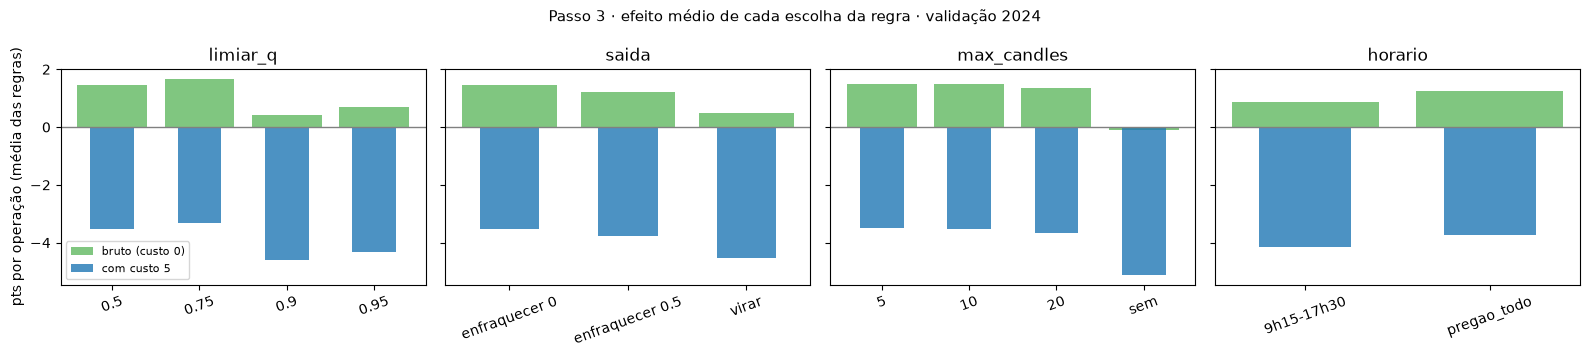

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, fator in zip(axes, ["limiar_q", "saida", "max_candles", "horario"]):
    e = efeitos[efeitos.fator == fator]
    ax.bar(e.opcao, e.bruto_medio, color="tab:green", alpha=.6, label="bruto (custo 0)")
    ax.bar(e.opcao, e.esperanca_media, color="tab:blue", alpha=.8, width=.5, label="com custo 5")
    ax.axhline(0, color="gray", lw=1); ax.set_title(fator); ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("pts por operação (média das regras)"); axes[0].legend(fontsize=8)
fig.suptitle("Passo 3 · efeito médio de cada escolha da regra · validação 2024", fontsize=11)
fig.tight_layout(); fig.savefig(f"{SAIDA}/regras_saida_efeitos.png", dpi=150); plt.show()

## Decisão do passo 3

In [5]:
cand = mod[mod.candidata].sort_values("retorno_capital", ascending=False)
if len(cand):
    v = cand.iloc[0]
    CRITERIO = "maior retorno sobre capital entre as candidatas"
    REGRA = dict(limiar_q=float(v.limiar_q), saida=v.saida, max_candles=str(v.max_candles), horario=v.horario)
else:
    CRITERIO = "nenhuma candidata: regra decidida no fim, com o modelo final"
    REGRA = None
melhor = mod.sort_values("esperanca_pts", ascending=False).iloc[0]
print("Critério:", CRITERIO)
print(f"Melhor regra (diagnóstico): limiar {melhor.limiar_q:.0%}, saída {melhor.saida}, máx. {melhor.max_candles}, "
      f"{melhor.horario} | {melhor.esperanca_pts:+.2f} pts/op (t {melhor.t_stat:.2f}) | {melhor.candles_medios:.1f} candles "
      f"| trimestres + {melhor.trimestres_positivos}/4")
json.dump(dict(passo="3 - regra de saída", criterio=CRITERIO, regra=REGRA, n_candidatas=int(len(cand)),
               melhor_diagnostico=dict(limiar_q=float(melhor.limiar_q), saida=melhor.saida,
                                       max_candles=str(melhor.max_candles), horario=melhor.horario,
                                       esperanca_pts=float(melhor.esperanca_pts), t_stat=float(melhor.t_stat))),
          open(f"{SAIDA}/decisao_passo3.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

Critério: nenhuma candidata: regra decidida no fim, com o modelo final
Melhor regra (diagnóstico): limiar 75%, saída virar, máx. sem, pregao_todo | -1.87 pts/op (t -1.30) | 12.8 candles | trimestres + 2/4
